In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
from matplotlib.ticker import MultipleLocator

import seaborn as sns
import os
import datetime
import pickle

from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from astropy.stats import kuiper
from scipy.stats import pearsonr
from scipy.stats import entropy
from scipy import stats


from scipy.stats import ranksums, ttest_ind, ttest_rel, f_oneway, false_discovery_control, mannwhitneyu
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from src.model import linearreg

### Supporting functions

In [5]:
## color palette of bars in the MSE plot
colornums = sns.color_palette(palette='Blues', n_colors=6, as_cmap=False)
blues_palette_hex = list(colornums.as_hex())

setpairedcolorlist = sns.color_palette('Paired')
setpairedred = setpairedcolorlist[5]
setpairedgreen = setpairedcolorlist[3]
setpairedblue = setpairedcolorlist[1]
setpairedlightblue = setpairedcolorlist[0]


### Load files

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'  # interval or not?

outsupfig_dir = 'output/circpaper_figures/supp/'

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    df['RX_norm'] = (df['Episode starts with RX'] - df['Episode starts with RX'].mean()) / df['Episode starts with RX'].std()
    max_hour = df.groupby(by='Local_hour')['Episode starts with RX'].mean().idxmax()
    df['Maxalgn_hour'] = (df['Local_hour'] - max_hour)  % 24
    df['Maxalgn_mid_hour'] = ( df['Maxalgn_hour'] - 12 ) % 24
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
MIN_LS_NSAMP = 120   # 120 MAGIC for interval LS models, 0 otherwise
lsdata_cols = ['amp_unnorm_%s', 'amp_norm_%s', 'peakhour_%s', 'fitpower_%s', 'pvalue_%s']


# read the cycle charateristics csv file and store in a dictionary
lsdf_dict = {}

for patient_id in patient_list:
    
    if not os.path.exists(lsdf_path % (patient_id)):
        print(f'{patient_id}: No LS file found. Removing from patient list.')
        continue
    
    lsdf = pd.read_csv(lsdf_path % (patient_id))  # read Ls file
    
    pat_days_list = [int(item.split('_')[-1]) for item in lsdf.columns if ('nsamp' in item)]
    
    # blank out times with samples less than some threshold
    for daynum in pat_days_list:
        if lsdf[f'nsamp_{daynum}'].iloc[0] < MIN_LS_NSAMP:
            pat_lsdata_cols = [item%(daynum) for item in lsdata_cols]
            lsdf[pat_lsdata_cols] = np.NaN
    
    # store the dataframe
    lsdf_dict[patient_id] = lsdf.copy()

In [11]:
feature_list = lsdf_dict[patient_list[0]]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs

subfeatdict = ccutils.get_subfeatdict(feature_list, band_list, edge_type_list)

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[2, 2, 2, 2, 8]


In [12]:
normtype = 'zeroone'  # 'zeroone', 'maxnorm'
lgmscdict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['dur_halfyr', 'Local_hour'], 
                                    normtype=normtype)

In [13]:
interval_start = 7   # MAGIC; change based on normtype. zeroone=7, maxnorm=5
interval_end = 11

lgaucdf = ccutils.longi_interval_aucdf(lgmscdict, patient_list, interval_start, interval_end, verbose=True)

Dropped entries because stim AUC=0: # 9


In [14]:
### characteristics

pvaldf = []

for patient_id in patient_list:
    # read dictionary
    lsdf = lsdf_dict[patient_id].copy()
    lsdf.dropna(axis=1, inplace=True)    # drop the column
    
    # get feature list
    featcols = [item for item in lsdf.columns if ('pvalue' in item)]

    # melt dataframe
    pvaldf.append(lsdf.loc[lsdf['feature'].isin(subfeatdict['local']['all'])].dropna(axis=1).melt(id_vars=['npecode','feature'], 
                                                                                                   value_vars=featcols))

## convert to dataframe
pvaldf = pd.concat(pvaldf, axis=0, ignore_index=True)

## extract information
pvaldf['feat_days'] = pvaldf['variable'].apply(lambda x: int(x.split('_')[-1]))
pvaldf['band'] = pvaldf['feature'].apply(lambda x: x.split('_')[-1])
pvaldf['sig'] = pvaldf['value'].apply(lambda x: 1 if x < 0.05 else 0)   # whether pvalue is less than significance threshold

In [15]:
## organized by 6 months information
pvaluecounts = pvaldf.groupby(by=['npecode', 'band', 'feat_days'])['sig'].sum()
pvaluecounts = pvaluecounts.reset_index()
pvaluecounts.rename(columns={'sig':'sigcycles'}, inplace=True)

### Circadian concordance alpha biomarker

In [16]:
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']
tltype = 'causal'  # 'causal' or 'noncausal'
mreg_id_vars = ['npecode', 'feat_days', 'baseline_seizure_rate', 'outcome_days', 'sz_red', 'auc']
                # 'auc', 'auc_interval', 'auc_converse', 'max_hour', 'sin_hour', 'cos_hour']
mreg_value_vars = ['amp_unnorm_local', 'peakhour_local']

# FC-CC features
lgfeatdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, patient_list, band_list, edge_type_list, subfeatdict)

# # combine stimulation feature with FC-CC features
# lgfeatdf = lgaucdf.merge(lgfeatdf, how='left', left_on=['npecode', 'dur_day'],
#                      right_on=['npecode', 'days_from_implant'])
lgfeatdf['auc'] = 1 ### dummy

# combine features with seizure reduction information
mregdf = ccutils.create_cop_dataframe(lgpatcodesdf, lgfeatdf, patient_list, mreg_id_vars, mreg_value_vars, tltype, 
                                      verbose=True)

print('Num samples:', mregdf.shape[0])

### only keep significant ones
nzpvcounts = pvaluecounts.loc[(pvaluecounts['band']=='alpha') & (pvaluecounts['sigcycles'] > 0)].copy()
mregdf = mregdf.merge(nzpvcounts, how='inner', on=['npecode', 'feat_days'])

print('Num samples:', mregdf.shape[0])

Dropped nans in regdf: 0
Num samples: 77
Num samples: 56


PearsonRResult(statistic=0.5033390014075388, pvalue=7.683011721425521e-05)
Num samples: 56


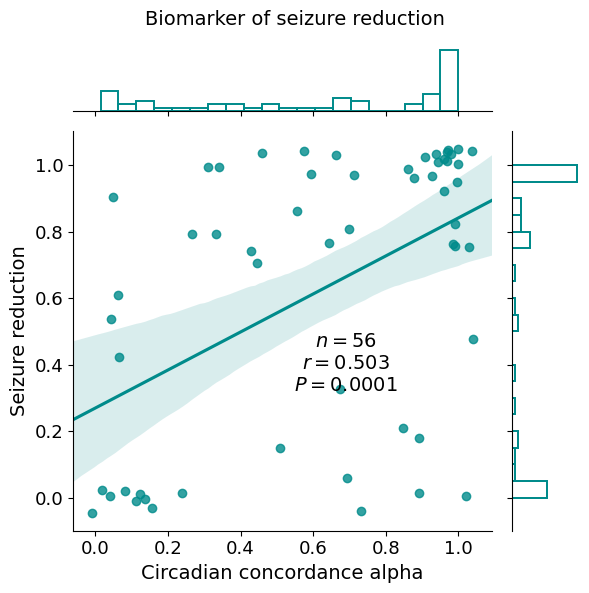

In [17]:
xfeat = 'peakhour_local-alpha'
yvar = 'sz_red'
band = 'alpha'

xcorr = mregdf[xfeat].values
ycorr = mregdf[yvar].values
n_samp = len(xcorr)

corrres = pearsonr(xcorr, ycorr)
print(corrres)
print(f'Num samples: {len(xcorr)}')


ax = sns.jointplot(x=xfeat, y=yvar, data=mregdf,
                   kind="reg", truncate=False, color='darkcyan',
                   marginal_kws=dict(bins=20, kde=False, fill=False), 
                   joint_kws={'x_jitter': 0.05, 'y_jitter': 0.05})


plt.text(x=0.65, y=0.35, 
         s='$n=%d$\n$r=%0.3f$\n$P=%0.4f$'%(n_samp, corrres.statistic, corrres.pvalue), 
         transform=ax.ax_joint.transAxes, fontsize=14, ha='center')

plt.xlabel(f'Circadian concordance {band}', fontsize=14)
plt.ylabel('Seizure reduction', fontsize=14)
plt.tick_params(labelsize=13)

ax.fig.suptitle('Biomarker of seizure reduction', fontsize=14)

ax.fig.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'lsccbio_cc_alpha_jointplot_jittered.pdf', dpi=300)

plt.show()

In [18]:
## mixed effect model
rnmregdf = mregdf.copy()
rnmregdf.rename(columns={'peakhour_local-alpha':'peakhour_local_alpha'}, inplace=True)

rmcorr = utils.corr_repeated_measures(data=rnmregdf, x="peakhour_local_alpha", y='sz_red', groups='npecode')
print(f"Correlation={rmcorr['corr']}, pvalue={rmcorr['pvalue']}")

Correlation=0.3692984313722429, pvalue=0.0018369627567322946


## Prediction models

In [19]:
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']
tltype = 'causal'  # 'causal' or 'noncausal'
mreg_id_vars = ['npecode', 'feat_days', 'baseline_seizure_rate', 'outcome_days', 'sz_red', 
                'auc', 'auc_interval', 'auc_converse', 'max_hour', 'sin_hour', 'cos_hour']
mreg_value_vars = ['amp_unnorm_local', 'peakhour_local']

# FC-CC features
lgfeatdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, patient_list, band_list, edge_type_list, subfeatdict)

# combine stimulation feature with FC-CC features
lgfeatdf = lgaucdf.merge(lgfeatdf, how='left', left_on=['npecode', 'dur_day'],
                     right_on=['npecode', 'days_from_implant'])

# combine features with seizure reduction information
mregdf = ccutils.create_cop_dataframe(lgpatcodesdf, lgfeatdf, patient_list, mreg_id_vars, mreg_value_vars, tltype, 
                                      verbose=True)

print('Num samples all epoch:', mregdf.shape[0])

### only keep significant ones
nzpvcounts = pvaluecounts.loc[(pvaluecounts['band']=='alpha') & (pvaluecounts['sigcycles'] > 0)].copy()
mregdf = mregdf.merge(nzpvcounts, how='inner', on=['npecode', 'feat_days'])

print('Num samples epochs with at least one sig cycle:', mregdf.shape[0])

Dropped nans in regdf: 0
Num samples all epoch: 72
Num samples epochs with at least one sig cycle: 51


### recursive feature selection

In [20]:
# recusive feature elimination for a range of feature sets

feat_sz = ['log_baseline_seizure_rate']

feat_fccc_amp = ['amp_unnorm_local-theta', 'amp_unnorm_local-alpha', 
                 'amp_unnorm_local-beta', 'amp_unnorm_local-gamma']

feat_fccc_ps = ['peakhour_local-theta', 'peakhour_local-alpha', 
                'peakhour_local-beta', 'peakhour_local-gamma']

feat_stim = ['auc_converse', 'sin_hour', 'cos_hour']

feat_all = feat_sz + feat_fccc_amp + feat_fccc_ps + feat_stim

fullfeatdict = {'sz': feat_sz , 'fccc_amp': feat_fccc_amp, 'fccc_ps': feat_fccc_ps, 
                'fccc': feat_fccc_amp + feat_fccc_ps, 'stim': feat_stim, 'all': feat_all}

yvar = 'sz_red'

rfefeatdict = {}

for featkey, regfeats in fullfeatdict.items():
    print(featkey)
    # recursive feature elimination
    final_regfeats = linearreg.recursive_feature_elimination(regdf=mregdf, full_feature_list=regfeats, yvar=yvar, 
                                                             cv_folds_list=patient_list, cv_var='npecode', 
                                                             remove_outliers=False)

    print('Final feature list:', final_regfeats)
    
    # store the features
    rfefeatdict[featkey] = final_regfeats

sz
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue    0
dtype: int64
Final feature list: []
fccc_amp
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    3
amp_unnorm_local-alpha__pvalue    0
amp_unnorm_local-beta__pvalue     6
amp_unnorm_local-gamma__pvalue    3
dtype: int64
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    7
amp_unnorm_local-beta__pvalue     6
amp_unnorm_local-gamma__pvalue    3
dtype: int64
Final feature list: ['amp_unnorm_local-theta', 'amp_unnorm_local-beta', 'amp_unnorm_local-gamma']
fccc_ps
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 p

Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue     0
amp_unnorm_local-alpha__pvalue     0
amp_unnorm_local-beta__pvalue      1
amp_unnorm_local-gamma__pvalue    22
peakhour_local-theta__pvalue       0
peakhour_local-alpha__pvalue      23
peakhour_local-beta__pvalue        1
peakhour_local-gamma__pvalue       0
dtype: int64
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-beta__pvalue      0
amp_unnorm_local-gamma__pvalue    19
peakhour_local-alpha__pvalue      23
peakhour_local-beta__pvalue        0
dtype: int64
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-gamma__pvalue    15
peakhour_local-alpha__pvalue      23
dtype: int64
Final feature list: ['amp_unnorm_local-gamma', 'peakhour_local-alpha']
stim
Outliers N

Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 auc_converse__pvalue    22
dtype: int64
Final feature list: ['auc_converse']
all
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue     4
amp_unnorm_local-theta__pvalue        0
amp_unnorm_local-alpha__pvalue        0
amp_unnorm_local-beta__pvalue         1
amp_unnorm_local-gamma__pvalue       23
peakhour_local-theta__pvalue          0
peakhour_local-alpha__pvalue         21
peakhour_local-beta__pvalue           1
peakhour_local-gamma__pvalue          0
auc_converse__pvalue                  0
sin_hour__pvalue                      1
cos_hour__pvalue                      0
dtype: int64
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue     7
amp_unnorm_local-beta__pvalue

In [21]:
## include baseline seizure rate
rfefeatdict['sz'] = ['log_baseline_seizure_rate']

yvar = 'sz_red'


gppreddf = []  # all the predictions for all the feature sets
gpmsedf = []   # MSE for each fold for all the feature sets
cmmsedf = []   # grand total MSE (combined MSE) for all the feature sets
cmllfdf = []   # combined log likelihood of trained model for all the feature sets

for featkey, regfeats in rfefeatdict.items():
    
    print(f'\n{featkey}')
    
    # linear regression cross-validation
    lmpreddf, linmoddict = linearreg.cross_validation(regdf=mregdf, regfeat_cols=regfeats, yvar=yvar, 
                                                     cv_folds_list=patient_list, cv_var='npecode', 
                                                     remove_outliers=False)
    
    # store predictions
    if featkey == 'sz':
        gppreddf.append(lmpreddf.rename(columns={'modpred':featkey}))
    else:
        gppreddf.append(lmpreddf['modpred'].rename(featkey))
    
    # compute MSE
    if featkey == 'sz':
        diff_tuples = [('gt','modpred', f'{featkey}_mse'), ('gt','basemean','base_mse')]
    else:
        diff_tuples = [('gt','modpred', f'{featkey}_mse')]
        
    lmmsedf = linearreg.foldwise_mse(preddf=lmpreddf, cv_var='npecode', diff_tuples=diff_tuples)
    
    feat_cmmsedf = linearreg.combined_mse(preddf=lmpreddf, diff_tuples=diff_tuples)
    
    gpmsedf.append(lmmsedf.copy())
    cmmsedf.append(feat_cmmsedf)
    
    # number of times a coefficient was significant
    lmsummary = linearreg.summarize_model_cv(linmoddict, cv_var='npecode')
    print((lmsummary[[item for item in lmsummary.columns if '__pvalue' in item]] < 0.05).sum())
    
    # combined loglikeihood of training data
    cmllfdf.append(pd.DataFrame({featkey: [linearreg.combined_llf(linmoddict)]}))

# concatenate
gppreddf = pd.concat(gppreddf, axis=1, ignore_index=False)
gpmsedf = pd.concat(gpmsedf, axis=1, ignore_index=False)
cmmsedf = pd.concat(cmmsedf, axis=1, ignore_index=False)
cmllfdf = pd.concat(cmllfdf, axis=1, ignore_index=False)


sz
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
log_baseline_seizure_rate__pvalue     0
const__pvalue                        23
dtype: int64

fccc_amp
Outliers NOT removed. Num entries: 51.


Clipped output between 0-1.
Cross-validation complete.
amp_unnorm_local-theta__pvalue     7
amp_unnorm_local-beta__pvalue      6
amp_unnorm_local-gamma__pvalue     3
const__pvalue                     23
dtype: int64

fccc_ps
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
peakhour_local-alpha__pvalue    23
const__pvalue                   23
dtype: int64

fccc
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
amp_unnorm_local-gamma__pvalue    15
peakhour_local-alpha__pvalue      23
const__pvalue                     23
dtype: int64

stim
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
auc_converse__pvalue    22
const__pvalue           23
dtype: int64


/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[0]] - x[tup[1]]) ** 2).mean() )
/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[


all
Outliers NOT removed. Num entries: 51.
Clipped output between 0-1.
Cross-validation complete.
log_baseline_seizure_rate__pvalue     2
amp_unnorm_local-gamma__pvalue       23
peakhour_local-alpha__pvalue         23
sin_hour__pvalue                     22
const__pvalue                        23
dtype: int64


In [22]:
rfefeatdict

{'sz': ['log_baseline_seizure_rate'],
 'fccc_amp': ['amp_unnorm_local-theta',
  'amp_unnorm_local-beta',
  'amp_unnorm_local-gamma'],
 'fccc_ps': ['peakhour_local-alpha'],
 'fccc': ['amp_unnorm_local-gamma', 'peakhour_local-alpha'],
 'stim': ['auc_converse'],
 'all': ['log_baseline_seizure_rate',
  'amp_unnorm_local-gamma',
  'peakhour_local-alpha',
  'sin_hour']}

### Clinical Prediction MSE

In [23]:
cmmsedf_norm = 100 * (cmmsedf['base_mse'].item() - cmmsedf) / cmmsedf['base_mse'].item()
mse_xtldict = {'sz': 'Sz.', 'fccc_amp': 'CA', 'fccc_ps': 'CC', 
               'fccc': 'CA and CC', 'stim': 'Stim.', 'all': 'All'}

# non filtered cmmsedf norm (from Figure 2 file)
cmmsedf_norm_nofl = pd.DataFrame(
    {'sz_mse': {0: -7.0322146547431625},
     'base_mse': {0: 0.0},
     'fccc_amp_mse': {0: 0.0},
     'fccc_ps_mse': {0: 8.511233536657018},
     'fccc_mse': {0: 14.310578030858673},
     'stim_mse': {0: 11.508900816625133},
     'all_mse': {0: 21.285417608376182}})

In [24]:
# combine all / sig cycle performances for comparison
cmmsedf_both = pd.concat((cmmsedf_norm.T.rename(columns={0:'sig_ls'}), 
                          cmmsedf_norm_nofl.T.rename(columns={0:'all_ls'})), axis=1, ignore_index=False)
cmmsedf_both.reset_index(names='feats', inplace=True)
cmmsedf_both = cmmsedf_both.melt(id_vars='feats', value_vars=['sig_ls', 'all_ls'], var_name='cycletype', value_name='mse')
cmmsedf_both.drop(index=cmmsedf_both.index[cmmsedf_both['feats']=='base_mse'], inplace=True)

/var/folders/gd/6nx8h5_s2pl0kp6dz_b6wn300000gn/T/ipykernel_46487/106703465.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])


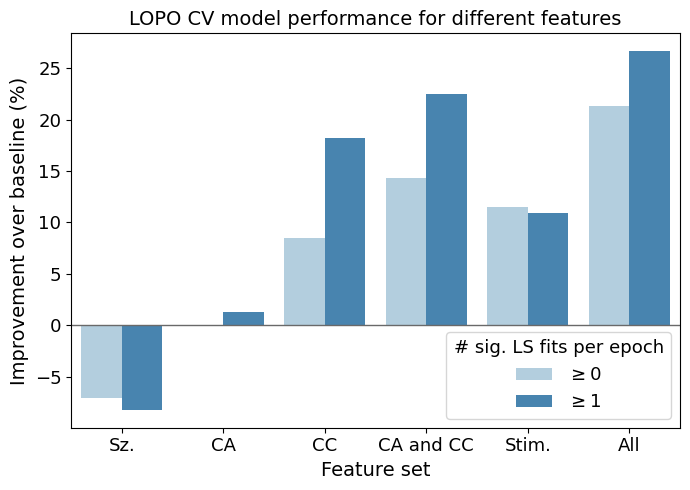

In [25]:
feature_set_list = ['sz_mse', 'fccc_amp_mse', 'fccc_ps_mse', 'fccc_mse', 'stim_mse', 'all_mse']

fig, ax = plt.subplots(1,1, figsize=(7,5))
sns.barplot(data=cmmsedf_both, x='feats', y='mse', hue='cycletype', hue_order=['all_ls', 'sig_ls'], 
            ax=ax, palette='Blues')
ax.axhline(y=0, linewidth=1, color='dimgray')

# format legend
moleghan, moleglab = ax.get_legend_handles_labels()
moleglab = ['$\geq 0 $', '$\geq 1$']
ax.legend(moleghan, moleglab, loc='lower right', title='# sig. LS fits per epoch', 
          fontsize=13, title_fontsize=13)

ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])
ax.set_xlabel('Feature set', fontsize=14)
ax.set_ylabel('Improvement over baseline (%)', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title('LOPO CV model performance for different features', fontsize=14)

fig.tight_layout()

if save_flag:
    fig.savefig(outsupfig_dir + 'lsccbio_clinpred_mse.pdf', dpi=300)

plt.show()


### Clustering of circadian cycle peaks

In [26]:
### peak hour and pvalue of LS model fit

charsdf = []

for patient_id in patient_list:
    # read dictionary
    lsdf = lsdf_dict[patient_id].copy()
    lsdf.dropna(axis=1, inplace=True)    # drop the column
    
    # get feature list
    featcols = [item for item in lsdf.columns if ('peakhour' in item) or ('pvalue' in item)]

    # melt dataframe
    charsdf.append(lsdf.loc[lsdf['feature'].isin(subfeatdict['local']['alpha'])].dropna(axis=1).melt(id_vars=['npecode','feature'], 
                                                                                                   value_vars=featcols))

## convert to dataframe
charsdf = pd.concat(charsdf, axis=0, ignore_index=True)

## extract information
charsdf['charac'] = charsdf['variable'].apply(lambda x: '_'.join(x.split('_')[:-1]))
charsdf['feat_days'] = charsdf['variable'].apply(lambda x: int(x.split('_')[-1]))
charsdf['band'] = charsdf['feature'].apply(lambda x: x.split('_')[-1])

## 
charsdf = charsdf.pivot(index=['npecode', 'feature', 'feat_days'], columns='charac', values='value').reset_index()

In [27]:
fccc_peak_hour_list = charsdf.loc[charsdf['pvalue'] < 0.05]['peakhour'].values

# the data is distributed non-uniformly
print(f"Uniformity test: n = {len(fccc_peak_hour_list)}, p = {kuiper(fccc_peak_hour_list/24)[1]}")

Uniformity test: n = 228, p = 3.1608389298276755e-09


In [28]:
def number_to_hourmin(nums):
    return ["%d:%0.2d"%(np.floor(num), np.round((num - np.floor(num)) * 60) ) for num in nums]

In [29]:
n_iters = 100

# Transform to 2D coordinates
angular_x = np.cos(np.pi/12 * fccc_peak_hour_list)
angular_y = np.sin(np.pi/12 * fccc_peak_hour_list)
angular_data = np.column_stack([angular_x, angular_y])
fine_grained_angles = np.linspace(start=0, stop=2*np.pi, num=480)

clustermeans = []
transition_hours = []

for _ in range(n_iters):
    # Cluster in 2D space
    gaussmixmod = GaussianMixture(n_components=2).fit(angular_data)
    
    # store clusters
    dayclusindex = 0 if gaussmixmod.means_[0][0] < 0 else 1
    clusmeanday = 12 / np.pi * ( np.arctan(gaussmixmod.means_[dayclusindex][1] / gaussmixmod.means_[dayclusindex][0]) + np.pi ) 
    clusmeannight = 12 / np.pi * ( np.arctan(gaussmixmod.means_[1 - dayclusindex][1] / gaussmixmod.means_[1 - dayclusindex][0]) ) 
    clustermeans.append([clusmeanday, clusmeannight])
    
    # store transition points
    # transition from one cluster to another in probability to compute edge
    fine_grained_probs = gaussmixmod.predict_proba(np.column_stack([np.cos(fine_grained_angles), np.sin(fine_grained_angles)]))
    fine_grained_prob_diff = -1 * np.abs( fine_grained_probs[:,1] - fine_grained_probs[:,0] ) + 1  
    transition_hours.append( fine_grained_angles[find_peaks(fine_grained_prob_diff)[0]] * 12 / np.pi )

# get average
print("Average cluster centers (hr):", number_to_hourmin( np.array(clustermeans).mean(axis=0) ) )
print("Standard deviation of cluster centers (mins):", np.round( np.array(clustermeans).std(axis=0) * 60, 1 ) )
print("\n")
print("Average cluster boundaries (hr):", number_to_hourmin( np.array(transition_hours).mean(axis=0) ) )
print("Standard deviation of cluster boundaries (mins):", np.round( np.array(transition_hours).std(axis=0) * 60, 1 ) )

Average cluster centers (hr): ['14:44', '3:18']
Standard deviation of cluster centers (mins): [0. 0.]


Average cluster boundaries (hr): ['8:37', '20:57']
Standard deviation of cluster boundaries (mins): [0. 0.]


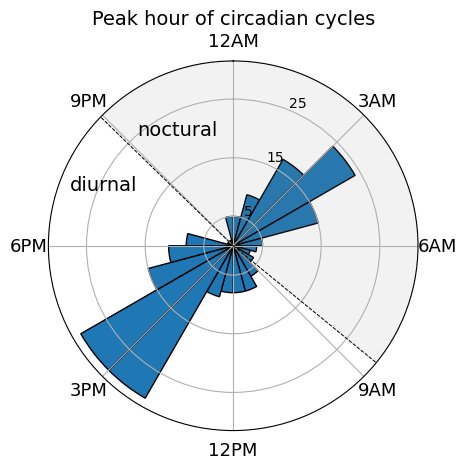

In [30]:
time_low, time_high = np.array(transition_hours).mean(axis=0)   ## define boundaries from data

# Create polar subplot
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

# Create histogram
ax.hist(np.pi/12 * fccc_peak_hour_list, bins=np.linspace(0, 2*np.pi, 25), 
        color=setpairedblue, edgecolor='k', alpha=1.0)

ax.axvspan(xmin=(time_high-24) * np.pi/12, 
           xmax=time_low * np.pi/12, color='grey', alpha=0.1)

# cluster boundaries
ax.axvline(x=time_low * np.pi/12, color='k', linestyle='--', linewidth=0.7)
ax.axvline(x=time_high * np.pi/12, color='k', linestyle='--', linewidth=0.7)

# Customize plot
ax.set_theta_zero_location("N")  # Set 0 at the top
ax.set_theta_direction(-1)      # Clockwise direction
ax.set_xticks(ticks=[0, np.pi/4, 2*np.pi/4, 3*np.pi/4, 
                     np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4], 
              labels=['12AM', '3AM', '6AM', '9AM', 
                      '12PM', '3PM', '6PM', '9PM'], fontsize=13)
ax.set_yticks(ticks=[5,15,25])

ax.text(x=0.35, y=0.8, s='noctural', fontsize=14, color='black', ha='center',
        transform=ax.transAxes)
ax.text(x=0.15, y=0.65, s='diurnal', fontsize=14, color='black', ha='center',
        transform=ax.transAxes)

plt.title('Peak hour of circadian cycles', fontsize=14)

if save_flag:
    plt.savefig(outsupfig_dir + 'lsccbio_cc_peak_dist.pdf', dpi=300)

plt.show()